# Caso TakeHome 04 — Shortfall di margine condizionato a regimi del costo dell'energia

## 1. Titolo e contesto del caso

- **Lezione:** Lezione 04 — Applicazione in Python: probabilità, variabili casuali e valori attesi condizionati.
- **Tipo di caso:** TakeHome.
- **Titolo:** *Shortfall di margine condizionato a regimi del costo dell'energia*.
- **Contesto:** impresa manifatturiera energivora esposta all'incertezza del prezzo dell'energia.
- **Domanda quantitativa:** qual è la distribuzione dello shortfall di margine e come cambia lo shortfall atteso condizionando sui diversi regimi del costo dell'energia?
- **Variabile finale:** shortfall di margine

$$
S=(m^\star-M)^+=(m^\star-G_0+Q_EP_E)^+.
$$

- **Informazione disponibile:** partizione dello spazio degli esiti

$$
\Omega=A_1\cup A_2\cup A_3,\qquad A_i\cap A_j=\emptyset\quad (i\neq j),
$$

con sigma-algebra informativa

$$
\mathcal G=\sigma(A_1,A_2,A_3),
$$

e distribuzioni condizionate

$$
P_E\mid A_g\sim\mathcal N(\mu_g,\sigma_g^2),\qquad g=1,2,3.
$$

La simulazione ha finalità didattica e non previsionale.

---

## 2. Quantità da stimare o calcolare

### Quantità non condizionate

1. Valore atteso dello shortfall: $\mathbb E[S]$.
2. Probabilità di shortfall positivo: $\mathbb P(S>0)$.
3. Probabilità di shortfall severo: $\mathbb P(S>s^\star)$.
4. Quantili dello shortfall: $q_\alpha(S)$.

### Quantità condizionate

1. Medie condizionate per regime:

$$
\mathbb E[S\mid A_g],\qquad g=1,2,3.
$$

2. Valore atteso condizionato rispetto all'informazione di regime:

$$
\mathbb E[S\mid\mathcal G]
=\sum_{g=1}^{3}\mathbb E[S\mid A_g]\mathbf 1_{A_g}.
$$

3. Formula del valore atteso totale:

$$
\mathbb E[S]
=\sum_{g=1}^{3}\mathbb P(A_g)\mathbb E[S\mid A_g].
$$

Nel notebook devono restare distinti il numero $\mathbb E[S\mid A_g]$, la variabile casuale $\mathbb E[S\mid\mathcal G]$ e il valore atteso non condizionato $\mathbb E[S]$.

---

## 3. Output richiesti

### Tabelle

1. **Tabella dei parametri:** dati economico-finanziari, probabilità dei regimi, parametri condizionati e soglie implicite.
2. **Tabella di controllo della simulazione:** frequenze empiriche dei regimi e media/deviazione standard empirica di $P_E\mid A_g$.
3. **Tabella descrittiva delle grandezze principali:** almeno $P_E$, $M$ e $S$, con media, deviazione standard e principali statistiche descrittive.
4. **Tabella delle quantità di rischio:** $\widehat{\mathbb P}(S>0)$, $\widehat{\mathbb P}(S>s^\star)$, quantili principali e $\widehat{\mathbb E}[S\mid A_g]$ per i tre regimi.
5. **Tabella di verifica del valore atteso totale:** confronto tra media globale dello shortfall e media pesata delle medie condizionate.

### Grafici

1. **Distribuzione empirica del prezzo dell'energia $P_E$.**
2. **Distribuzione empirica del margine operativo $M$.**
3. **Distribuzione empirica dello shortfall $S$**, con evidenza della massa in zero e della soglia $s^\star$.
4. **Grafico delle medie condizionate** $\widehat{\mathbb E}[S\mid A_g]$.
5. **Confronto tra le distribuzioni condizionate dello shortfall.**

---

## 4. Controlli richiesti

1. Le probabilità dei regimi devono sommare a uno; le frequenze empiriche devono essere coerenti con esse e ciascun regime deve avere numerosità sufficiente.
2. Media e deviazione standard empiriche di $P_E\mid A_g$ devono essere coerenti con $\mu_g$ e $\sigma_g$.
3. Deve essere rilevata l'eventuale presenza di valori negativi di $P_E$; tali valori non devono essere eliminati senza motivazione.
4. Devono essere rispettate le relazioni $C_E=Q_EP_E$, $M=G_0-Q_EP_E$ e $S=(m^\star-M)^+$.
5. Deve risultare sempre $S\geq0$.
6. $\widehat{\mathbb P}(S>0)$ deve essere coerente con la soglia $P_E>120$ euro/MWh.
7. $\widehat{\mathbb P}(S>s^\star)$ deve essere coerente con la soglia $P_E>140$ euro/MWh.
8. La media globale di $S$ deve coincidere, salvo arrotondamenti, con la media pesata delle medie condizionate.
9. I quantili devono rispettare l'ordinamento atteso e la media deve cadere tra minimo e massimo campionario.

---

## 5. Vincolo della Scheda Caso

La Scheda Caso costituisce la **specifica vincolante del lavoro**. Variabili, formule, parametri, output, controlli e ipotesi non vengono modificati durante lo svolgimento.

# Flusso logico-teorico risolutivo — Caso TakeHome 04

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| **1** | Identificare la variabile economica finale e il legame con il fattore di rischio | $S=(m^\star-M)^+$, con $M=G_0-Q_EP_E$ | Lo shortfall $S$ è determinato dal prezzo dell'energia tramite costo energetico e margine operativo. | Formula da implementare; controllo $S\ge 0$; distinzione tra prezzo, costo, margine e shortfall. |
| **2** | Definire le soglie di rischio e tradurle nel fattore di rischio | $S>0\Longleftrightarrow P_E>(G_0-m^\star)/Q_E$ e $S>s^\star\Longleftrightarrow P_E>(G_0-m^\star+s^\star)/Q_E$ | Le soglie monetarie diventano soglie implicite sul prezzo unitario dell'energia. | Soglie $120$ e $140$ euro/MWh; $\widehat{\mathbb P}(S>0)$ e $\widehat{\mathbb P}(S>s^\star)$. |
| **3** | Rappresentare l'informazione di regime | $\Omega=A_1\cup A_2\cup A_3$, $A_i\cap A_j=\emptyset$ per $i\neq j$; $p_g=\mathbb P(A_g)$, $\sum_g p_g=1$ | I tre eventi rappresentano regimi del mercato energetico e guidano l'estrazione Monte Carlo del regime. | Tabella degli eventi; controllo $\sum_g p_g=1$; frequenze empiriche $\widehat{\mathbb P}(A_g)$. |
| **4** | Specificare il comportamento del fattore di rischio nei diversi regimi | $P_E\mid A_g\sim\mathcal N(\mu_g,\sigma_g^2)$ | Ogni regime genera prezzi dell'energia con media e volatilità diverse. | Parametri $(\mu_g,\sigma_g)$; controllo di media e deviazione standard empiriche; controllo $P_E<0$. |
| **5** | Costruire la distribuzione non condizionata tramite simulazione gerarchica | Campionamento gerarchico: prima $A_g$, poi $P_E\mid A_g$ | La distribuzione globale di $P_E$ nasce dalla combinazione tra probabilità dei regimi e distribuzioni condizionate. | Dataset con evento e $P_E$; distribuzione empirica di $P_E$; controlli sui regimi e sui prezzi condizionati. |
| **6** | Trasformare il prezzo simulato in costo, margine e shortfall | $C_{E,i}=Q_EP_{E,i}$, $M_i=G_0-Q_EP_{E,i}$, $S_i=(m^\star-M_i)^+$ | Da ogni prezzo simulato si ottengono costo energetico, margine operativo e shortfall. | Dataset con evento, $P_E$, $C_E$, $M$, $S$; controllo formula-codice; controllo dimensione $n$. |
| **7** | Produrre la lettura non condizionata del rischio | Distribuzione empirica, media, quantili, probabilità di superamento soglia | Si analizza la distribuzione globale dello shortfall senza distinguere i regimi. | Statistiche descrittive di $P_E$, $M$, $S$; $\widehat{\mathbb E}[S]$; quantili; $\widehat{\mathbb P}(S>0)$; $\widehat{\mathbb P}(S>s^\star)$; grafici globali. |
| **8** | Produrre la lettura condizionata per regime | $\mathbb E[S\mid A_g]$ | Si confronta lo shortfall atteso nei tre regimi energetici. | Medie condizionate; grafico delle medie; confronto delle distribuzioni condizionate dello shortfall. |
| **9** | Collegare l'informazione disponibile al valore atteso condizionato | $\mathbb E[S\mid\mathcal G]=\sum_g\mathbb E[S\mid A_g]\mathbf 1_{A_g}$ | La previsione condizionata è una variabile casuale costante sui blocchi della partizione. | Colonna $\widehat{\mathbb E}[S\mid\mathcal G]$; distinzione tra numero e variabile casuale a gradini. |
| **10** | Verificare la coerenza complessiva e interpretare il ruolo dell'informazione | $\mathbb E[S]=\sum_g\mathbb P(A_g)\mathbb E[S\mid A_g]$ | La media globale viene ricostruita come media pesata delle medie di regime; l'informazione modifica la distribuzione rilevante, ma non elimina l'incertezza. | Verifica del valore atteso totale; commento finale su regimi, massa in zero, soglie e limiti del modello. |

# Scomposizione del caso in tappe input-output — Caso TakeHome 04

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| **1** | Specifica teorica e parametri | Rendere operativa la specifica senza modificarla | Scheda Caso, $G_0,Q_E,m^\star,s^\star,n,seed$, probabilità, $(\mu_g,\sigma_g)$ | Parte positiva, partizione, distribuzioni condizionate, soglie | Definizione di parametri e strutture dati; calcolo delle soglie implicite | Tabelle iniziali e oggetti Python | Somma probabilità; soglie $120$ e $140$ | Simulazione della partizione | A/B |
| **2** | Simulazione della partizione informativa | Assegnare ogni replica a uno dei tre eventi | Probabilità $A_1,A_2,A_3$, $n$, seed | Partizione e probabilità degli eventi | Estrazione Monte Carlo delle etichette | Vettore dei regimi e frequenze empiriche | Frequenze vicine alle teoriche; etichette ammesse; numerosità | Simulazione condizionata di $P_E$ | B |
| **3** | Simulazione di $P_E\mid A_g$, margine e shortfall | Costruire il dataset simulato completo | Regimi, $(\mu_g,\sigma_g)$, $G_0,Q_E,m^\star$ | Distribuzioni condizionate; $C_E$, $M$, $S$ | Simulazione dei prezzi; calcolo di $C_E$, $M$, $S$ | Dataset e distribuzione empirica di $P_E$ | Dimensioni; $P_E<0$; formule; $S\ge0$ | Analisi globale del rischio | B |
| **4** | Distribuzione empirica e rischio non condizionato | Quantificare il rischio globale senza distinguere i regimi | Dataset con $P_E$, $M$, $S$; soglie $0$ e $s^\star$ | Distribuzione empirica, media, quantili, eventi di soglia | Statistiche descrittive, quantili, probabilità e grafici | Tabelle e grafici globali | Ordine quantili; media tra min e max; equivalenze di soglia; massa in zero | Confronto con analisi condizionata | B |
| **5** | Valori attesi condizionati e valore atteso totale | Quantificare l'effetto dell'informazione di regime | Dataset con evento e $S$ | $\mathbb E[S\mid A_g]$, $\mathbb E[S\mid\mathcal G]$, valore atteso totale | Medie condizionate, variabile a gradini, ricomposizione della media | Tabella delle medie; grafici condizionati; verifica del valore atteso totale | Differenza media globale/ricomposta; distinzione tra oggetti; controlli conclusivi | Interpretazione critica | B |
| **6** | Interpretazione critica e limiti | Leggere gli output senza sovrainterpretarli | Output e controlli delle tappe 1–5 | Ruolo dell'informazione, rischio residuo, parte positiva, limiti della normale | Commento finale autonomo | Sezione finale del notebook | Non confondere condizionamento con eliminazione del rischio; non trattare la simulazione come previsione | Chiusura del lavoro | — |

## Tappa 1 — Specifica teorica e parametri

**Regime B — Traduzione operativa in codice.**

### Richiesta della tappa

Disponiamo della specifica teorica validata e dei parametri $G_0,Q_E,m^\star,s^\star,n,seed$, delle probabilità dei tre eventi e dei parametri condizionati $(\mu_g,\sigma_g)$.

La tappa deve:

- definire i parametri senza modificarli;
- organizzare probabilità e parametri condizionati in strutture dati leggibili;
- calcolare le soglie implicite associate a $S>0$ e $S>s^\star$;
- produrre le tabelle iniziali;
- verificare che le probabilità dei tre regimi sommino a uno.

### Sintesi logica

- **Input:** Scheda Caso; $G_0,Q_E,m^\star,s^\star,n,seed$; $p_g$; $\mu_g$; $\sigma_g$.
- **Operazioni:** definizione degli oggetti Python e calcolo delle soglie di prezzo.
- **Output:** tabelle dei parametri, dei regimi, dei parametri condizionati e delle soglie implicite.
- **Controlli:** $\sum_g p_g=1$; soglie pari a $120$ e $140$ euro/MWh.
- **Uso successivo:** gli oggetti definiti alimentano la simulazione della partizione e delle distribuzioni condizionate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Parametri economico-finanziari e computazionali
G0 = 8_000_000.0          # euro
Q_E = 50_000.0            # MWh
m_star = 2_000_000.0      # euro
s_star = 1_000_000.0      # euro
n = 50_000
seed = 24_680

# Eventi e probabilità
regimi = ["A1", "A2", "A3"]
prob_regimi = pd.Series({"A1": 0.35, "A2": 0.45, "A3": 0.20}, name="Probabilita_teorica")

# Parametri delle distribuzioni condizionate P_E | A_g
mu = pd.Series({"A1": 75.0, "A2": 115.0, "A3": 170.0}, name="mu_euro_MWh")
sigma = pd.Series({"A1": 15.0, "A2": 25.0, "A3": 45.0}, name="sigma_euro_MWh")

# Soglie implicite sul prezzo dell'energia
p_star_shortfall = (G0 - m_star) / Q_E
p_star_severo = (G0 - m_star + s_star) / Q_E

# Tabelle iniziali
tabella_parametri = pd.DataFrame({
    "Grandezza": ["G0", "Q_E", "m_star", "s_star", "n", "seed"],
    "Valore": [G0, Q_E, m_star, s_star, n, seed],
    "Unita": ["euro", "MWh", "euro", "euro", "simulazioni", "-"]
})

tabella_regimi = pd.DataFrame({
    "Regime": regimi,
    "Descrizione": ["Normalizzazione energetica", "Tensione persistente", "Shock energetico severo"],
    "Probabilita_teorica": prob_regimi.values
})

tabella_condizionale = pd.DataFrame({
    "Regime": regimi,
    "mu_euro_MWh": mu.values,
    "sigma_euro_MWh": sigma.values
})

tabella_soglie = pd.DataFrame({
    "Evento": ["S > 0", "S > s_star"],
    "Soglia_P_E_euro_MWh": [p_star_shortfall, p_star_severo]
})

print("Tabella dei parametri economico-finanziari e computazionali")
display(tabella_parametri)
print("Regimi e probabilità teoriche")
display(tabella_regimi)
print("Parametri condizionati di P_E | A_g")
display(tabella_condizionale)
print("Soglie implicite sul prezzo dell'energia")
display(tabella_soglie)

somma_prob = prob_regimi.sum()
print(f"Controllo somma probabilità: {somma_prob:.12f}")
print(f"Soglia S>0: {p_star_shortfall:.2f} euro/MWh")
print(f"Soglia S>s*: {p_star_severo:.2f} euro/MWh")

assert np.isclose(somma_prob, 1.0)
assert np.isclose(p_star_shortfall, 120.0)
assert np.isclose(p_star_severo, 140.0)

# Generatore pseudo-casuale unico e riproducibile per le tappe successive
rng = np.random.default_rng(seed)

Tabella dei parametri economico-finanziari e computazionali


,Grandezza,Valore,Unita
0,G0,8000000.0,euro
1,Q_E,50000.0,MWh
2,m_star,2000000.0,euro
3,s_star,1000000.0,euro
4,n,50000.0,simulazioni
5,seed,24680.0,-


Regimi e probabilità teoriche


,Regime,Descrizione,Probabilita_teorica
0,A1,Normalizzazione energetica,0.35
1,A2,Tensione persistente,0.45
2,A3,Shock energetico severo,0.20


Parametri condizionati di P_E | A_g


,Regime,mu_euro_MWh,sigma_euro_MWh
0,A1,75.0,15.0
1,A2,115.0,25.0
2,A3,170.0,45.0


Soglie implicite sul prezzo dell'energia


,Evento,Soglia_P_E_euro_MWh
0,S > 0,120.0
1,S > s_star,140.0


Controllo somma probabilità: 1.000000000000
Soglia S>0: 120.00 euro/MWh
Soglia S>s*: 140.00 euro/MWh


## Tappa 2 — Simulazione della partizione informativa

**Regime B — Traduzione operativa in codice.**

### Richiesta della tappa

A partire dalle probabilità di $A_1,A_2,A_3$, dal numero di simulazioni $n$, dal seed e dalle etichette ammesse, assegnare ciascuna replica a uno dei tre eventi della partizione.

### Sintesi logica

- **Input:** $p_1=0.35$, $p_2=0.45$, $p_3=0.20$, $n=50.000$, seed $=24680$.
- **Operazione:** estrazione di $n$ etichette secondo le probabilità assegnate.
- **Output:** vettore dei regimi simulati e tabella delle frequenze empiriche.
- **Controlli:** frequenze empiriche vicine alle probabilità teoriche; nessuna etichetta estranea; numerosità positiva e sufficiente in ogni regime.
- **Uso successivo:** l'etichetta simulata determina quale distribuzione condizionata usare per generare $P_E$.

In [2]:
# Simulazione degli eventi della partizione
regime_sim = rng.choice(regimi, size=n, p=prob_regimi.loc[regimi].to_numpy())

df = pd.DataFrame({"Regime": regime_sim})

frequenze = df["Regime"].value_counts().reindex(regimi)
frequenze_emp = (frequenze / n).rename("Probabilita_empirica")

tabella_frequenze = pd.DataFrame({
    "Regime": regimi,
    "Numerosita": frequenze.values,
    "Probabilita_teorica": prob_regimi.loc[regimi].values,
    "Probabilita_empirica": frequenze_emp.loc[regimi].values,
    "Scarto_empirica_teorica": (frequenze_emp.loc[regimi] - prob_regimi.loc[regimi]).values
})

display(tabella_frequenze)

etichette_ammesse = set(df["Regime"].unique()) == set(regimi)
num_sufficienti = (frequenze.loc[regimi] > 1000).all()
max_scarto_freq = np.max(np.abs(frequenze_emp.loc[regimi] - prob_regimi.loc[regimi]))

print(f"Etichette ammesse: {etichette_ammesse}")
print(f"Numerosità sufficiente in ogni regime (>1000): {num_sufficienti}")
print(f"Massimo scarto assoluto frequenza-probabilità: {max_scarto_freq:.5f}")

assert etichette_ammesse
assert num_sufficienti

,Regime,Numerosita,Probabilita_teorica,Probabilita_empirica,Scarto_empirica_teorica
0,A1,17498,0.35,0.34996,-0.00004
1,A2,22506,0.45,0.45012,0.00012
2,A3,9996,0.20,0.19992,-0.00008


Etichette ammesse: True
Numerosità sufficiente in ogni regime (>1000): True
Massimo scarto assoluto frequenza-probabilità: 0.00012


## Tappa 3 — Simulazione di $P_E\mid A_g$, costo energetico, margine e shortfall

**Regime B — Traduzione operativa in codice.**

### Richiesta della tappa

Usare le etichette simulate e i parametri $(\mu_g,\sigma_g)$ per generare $P_E\mid A_g$; quindi calcolare

$$
C_E=Q_EP_E,\qquad M=G_0-Q_EP_E,\qquad S=(m^\star-M)^+.
$$

### Sintesi logica

- **Input:** etichette dei regimi, $(\mu_g,\sigma_g)$, $G_0,Q_E,m^\star$.
- **Operazioni:** simulazione gerarchica dei prezzi; trasformazione in costo, margine e shortfall.
- **Output:** dataset completo con `Regime`, `P_E`, `C_E`, `M`, `S`; tabella di controllo delle statistiche condizionate; distribuzione empirica globale di $P_E$.
- **Controlli:** dimensioni pari a $n$; coerenza di media e deviazione standard di $P_E\mid A_g$; rilevazione di $P_E<0$; rispetto delle formule; $S\ge0$.
- **Uso successivo:** il dataset completo alimenta l'analisi non condizionata e quella condizionata.

Prime osservazioni del dataset simulato


,Regime,P_E,C_E,M,S
0,A2,119.033848,5.951692e+06,2.048308e+06,0.000000
1,A2,129.678729,6.483936e+06,1.516064e+06,483936.431483
2,A1,66.561987,3.328099e+06,4.671901e+06,0.000000
3,A2,102.018552,5.100928e+06,2.899072e+06,0.000000
4,A1,82.273329,4.113666e+06,3.886334e+06,0.000000
5,A2,103.078609,5.153930e+06,2.846070e+06,0.000000
6,A2,72.599554,3.629978e+06,4.370022e+06,0.000000
7,A1,65.402370,3.270119e+06,4.729881e+06,0.000000
8,A2,106.796127,5.339806e+06,2.660194e+06,0.000000
9,A2,107.810176,5.390509e+06,2.609491e+06,0.000000


Controllo empirico di P_E | A_g


,Numerosita,Media_empirica,Dev_std_empirica,Media_teorica,Dev_std_teorica,Scarto_media,Scarto_rel_std
Regime,,,,,,,
A1,17498,74.879197,15.101017,75.0,15.0,-0.120803,0.006734
A2,22506,114.980761,24.910078,115.0,25.0,-0.019239,-0.003597
A3,9996,170.335067,44.648907,170.0,45.0,0.335067,-0.007802


Prezzi P_E < 0: 2 su 50000 (0.004000%)
I valori negativi, se presenti, vengono segnalati come limite della specificazione normale e non vengono troncati.
Dimensioni corrette: True
C_E = Q_E * P_E: True
M = G0 - Q_E * P_E: True
S = max(m_star - M, 0): True
S >= 0: True


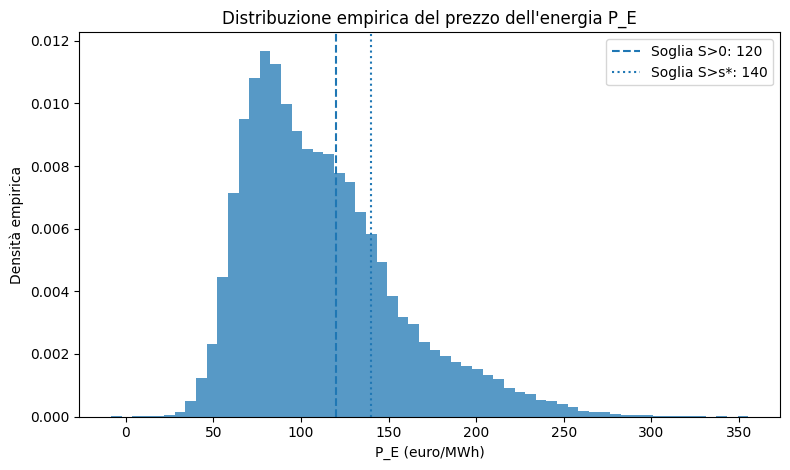

In [3]:
# Simulazione del prezzo P_E condizionatamente al regime estratto
P_E = np.empty(n, dtype=float)
for g in regimi:
    mask = df["Regime"].to_numpy() == g
    P_E[mask] = rng.normal(loc=mu[g], scale=sigma[g], size=mask.sum())

# Trasformazioni economiche
C_E = Q_E * P_E
M = G0 - C_E
S = np.maximum(m_star - M, 0.0)

df["P_E"] = P_E
df["C_E"] = C_E
df["M"] = M
df["S"] = S

print("Prime osservazioni del dataset simulato")
display(df.head(10))

# Controllo della simulazione condizionata
tabella_controllo_sim = (
    df.groupby("Regime")["P_E"]
      .agg(Numerosita="count", Media_empirica="mean", Dev_std_empirica="std")
      .reindex(regimi)
)
tabella_controllo_sim["Media_teorica"] = mu.loc[regimi]
tabella_controllo_sim["Dev_std_teorica"] = sigma.loc[regimi]
tabella_controllo_sim["Scarto_media"] = tabella_controllo_sim["Media_empirica"] - tabella_controllo_sim["Media_teorica"]
tabella_controllo_sim["Scarto_rel_std"] = (
    tabella_controllo_sim["Dev_std_empirica"] / tabella_controllo_sim["Dev_std_teorica"] - 1.0
)

print("Controllo empirico di P_E | A_g")
display(tabella_controllo_sim)

n_prezzi_negativi = int((df["P_E"] < 0).sum())
quota_prezzi_negativi = n_prezzi_negativi / n
print(f"Prezzi P_E < 0: {n_prezzi_negativi} su {n} ({quota_prezzi_negativi:.6%})")
print("I valori negativi, se presenti, vengono segnalati come limite della specificazione normale e non vengono troncati.")

# Controlli di identità e dimensione
controllo_dimensioni = all(len(df[col]) == n for col in ["P_E", "C_E", "M", "S"])
controllo_CE = np.allclose(df["C_E"], Q_E * df["P_E"])
controllo_M = np.allclose(df["M"], G0 - Q_E * df["P_E"])
controllo_S_formula = np.allclose(df["S"], np.maximum(m_star - df["M"], 0.0))
controllo_S_nonneg = bool((df["S"] >= 0).all())

print(f"Dimensioni corrette: {controllo_dimensioni}")
print(f"C_E = Q_E * P_E: {controllo_CE}")
print(f"M = G0 - Q_E * P_E: {controllo_M}")
print(f"S = max(m_star - M, 0): {controllo_S_formula}")
print(f"S >= 0: {controllo_S_nonneg}")

# Grafico richiesto: distribuzione empirica non condizionata di P_E
plt.figure(figsize=(8, 4.8))
plt.hist(df["P_E"], bins=60, density=True, alpha=0.75)
plt.axvline(p_star_shortfall, linestyle="--", label="Soglia S>0: 120")
plt.axvline(p_star_severo, linestyle=":", label="Soglia S>s*: 140")
plt.xlabel("P_E (euro/MWh)")
plt.ylabel("Densità empirica")
plt.title("Distribuzione empirica del prezzo dell'energia P_E")
plt.legend()
plt.tight_layout()
plt.show()

## Tappa 4 — Distribuzione empirica e rischio non condizionato

**Regime B — Traduzione operativa in codice.**

### Richiesta della tappa

Usare il dataset completo per descrivere $P_E$, $M$ e $S$, stimare la media dello shortfall, i quantili e le probabilità $S>0$ e $S>s^\star$, e rappresentare graficamente il margine e lo shortfall.

### Sintesi logica

- **Input:** dataset con $P_E$, $M$, $S$; soglie $0$ e $s^\star$.
- **Operazioni:** statistiche descrittive; quantili; frequenze di superamento; rappresentazione grafica.
- **Output:** tabella descrittiva, tabella delle quantità di rischio, grafico di $M$, grafico di $S$ con soglia, evidenza della massa in zero.
- **Controlli:** quantili ordinati; media tra minimo e massimo; equivalenza $S>0\Leftrightarrow P_E>120$; equivalenza $S>s^\star\Leftrightarrow P_E>140$; quota di massa in zero.
- **Uso successivo:** i risultati globali costituiscono il benchmark per il confronto tra regimi.

Statistiche descrittive di P_E, M e S


,Media,Dev_std,Min,Q05,Q25,Q50,Q75,Q90,Q95,Q99,Max
Variabile,,,,,,,,,,,
P_E,1.120133e+02,4.386558e+01,-8.423317e+00,5.770011e+01,7.911955e+01,1.036874e+02,1.354897e+02,1.731961e+02,2.007130e+02,2.440779e+02,3.553290e+02
M,2.399337e+06,2.193279e+06,-9.766450e+06,-2.035652e+06,1.225515e+06,2.815630e+06,4.044023e+06,4.764313e+06,5.114995e+06,5.755889e+06,8.421166e+06
S,7.048454e+05,1.399558e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.744847e+05,2.659807e+06,4.035652e+06,6.203896e+06,1.176645e+07


Quantità di rischio non condizionate


,Quantita,Valore
0,E_hat[S],7.048454e+05
1,P_hat(S>0),3.632600e-01
2,P_hat(S>s_star),2.216400e-01
3,q_0.50(S),0.000000e+00
4,q_0.90(S),2.659807e+06
5,q_0.95(S),4.035652e+06
6,q_0.99(S),6.203896e+06
7,P_hat(S=0),6.367400e-01


Equivalenza S>0 <=> P_E>120: True
Equivalenza S>s* <=> P_E>140: True
Quantili ordinati: True
Media S compresa tra minimo e massimo: True
Massa empirica in zero di S: 63.6740%


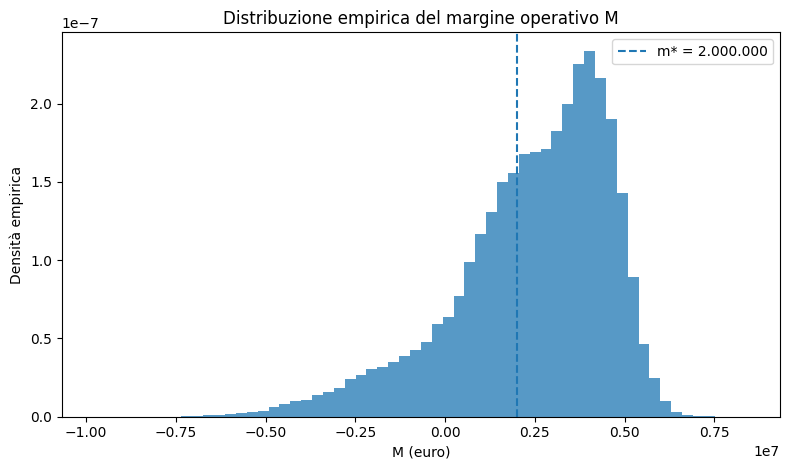

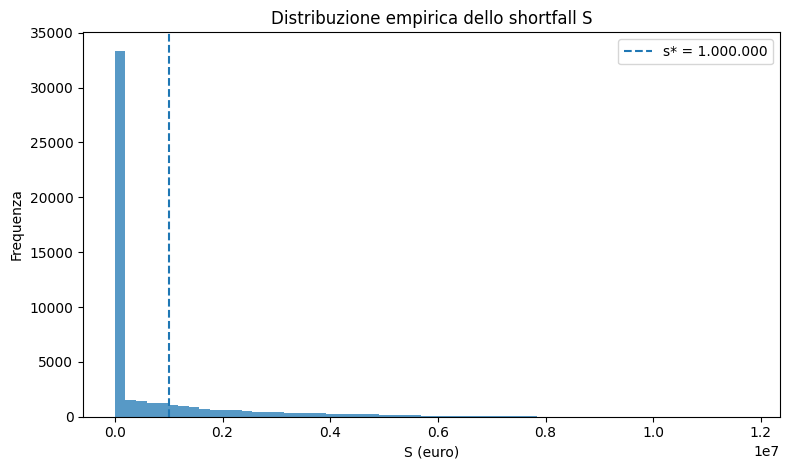

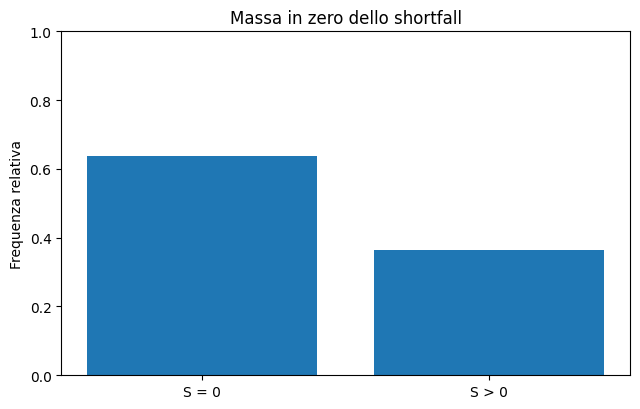

In [4]:
# Tabella descrittiva di P_E, M e S
quantili_descrittivi = [0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
righe = []
for var in ["P_E", "M", "S"]:
    x = df[var]
    q = x.quantile(quantili_descrittivi)
    riga = {
        "Variabile": var,
        "Media": x.mean(),
        "Dev_std": x.std(),
        "Min": x.min(),
        "Q05": q.loc[0.05],
        "Q25": q.loc[0.25],
        "Q50": q.loc[0.50],
        "Q75": q.loc[0.75],
        "Q90": q.loc[0.90],
        "Q95": q.loc[0.95],
        "Q99": q.loc[0.99],
        "Max": x.max(),
    }
    righe.append(riga)

tabella_descrittiva = pd.DataFrame(righe).set_index("Variabile")
print("Statistiche descrittive di P_E, M e S")
display(tabella_descrittiva)

# Quantità di rischio non condizionate
E_S = df["S"].mean()
P_S_pos = (df["S"] > 0).mean()
P_S_severo = (df["S"] > s_star).mean()
quantili_S = df["S"].quantile([0.50, 0.90, 0.95, 0.99])
massa_zero = (df["S"] == 0).mean()

tabella_rischio = pd.DataFrame({
    "Quantita": [
        "E_hat[S]",
        "P_hat(S>0)",
        "P_hat(S>s_star)",
        "q_0.50(S)",
        "q_0.90(S)",
        "q_0.95(S)",
        "q_0.99(S)",
        "P_hat(S=0)"
    ],
    "Valore": [
        E_S,
        P_S_pos,
        P_S_severo,
        quantili_S.loc[0.50],
        quantili_S.loc[0.90],
        quantili_S.loc[0.95],
        quantili_S.loc[0.99],
        massa_zero
    ]
})
print("Quantità di rischio non condizionate")
display(tabella_rischio)

# Controlli di soglia e statistiche
controllo_soglia_pos = np.array_equal((df["S"] > 0).to_numpy(), (df["P_E"] > p_star_shortfall).to_numpy())
controllo_soglia_severa = np.array_equal((df["S"] > s_star).to_numpy(), (df["P_E"] > p_star_severo).to_numpy())
controllo_quantili = bool(np.all(np.diff(quantili_S.to_numpy()) >= 0))
controllo_media_range = bool(df["S"].min() <= E_S <= df["S"].max())

print(f"Equivalenza S>0 <=> P_E>120: {controllo_soglia_pos}")
print(f"Equivalenza S>s* <=> P_E>140: {controllo_soglia_severa}")
print(f"Quantili ordinati: {controllo_quantili}")
print(f"Media S compresa tra minimo e massimo: {controllo_media_range}")
print(f"Massa empirica in zero di S: {massa_zero:.4%}")

# Grafico del margine operativo M
plt.figure(figsize=(8, 4.8))
plt.hist(df["M"], bins=60, density=True, alpha=0.75)
plt.axvline(m_star, linestyle="--", label="m* = 2.000.000")
plt.xlabel("M (euro)")
plt.ylabel("Densità empirica")
plt.title("Distribuzione empirica del margine operativo M")
plt.legend()
plt.tight_layout()
plt.show()

# Grafico dello shortfall S con soglia severa
plt.figure(figsize=(8, 4.8))
plt.hist(df["S"], bins=60, density=False, alpha=0.75)
plt.axvline(s_star, linestyle="--", label="s* = 1.000.000")
plt.xlabel("S (euro)")
plt.ylabel("Frequenza")
plt.title("Distribuzione empirica dello shortfall S")
plt.legend()
plt.tight_layout()
plt.show()

# Evidenza specifica della massa in zero
plt.figure(figsize=(6.5, 4.2))
quote = pd.Series({"S = 0": massa_zero, "S > 0": 1.0 - massa_zero})
plt.bar(quote.index, quote.values)
plt.ylabel("Frequenza relativa")
plt.title("Massa in zero dello shortfall")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Tappa 5 — Valori attesi condizionati e valore atteso totale

**Regime B — Traduzione operativa in codice.**

### Richiesta della tappa

Raggruppare lo shortfall per evento della partizione e calcolare le tre medie condizionate; costruire la controparte empirica di $\mathbb E[S\mid\mathcal G]$; confrontare le distribuzioni condizionate; verificare la formula del valore atteso totale e consolidare i controlli conclusivi.

### Sintesi logica

- **Input:** dataset con `Regime` e `S`; frequenze empiriche e probabilità teoriche.
- **Operazioni:** medie condizionate per blocco; mappatura della variabile a gradini; media pesata; confronto grafico tra regimi.
- **Output:** tabella $\widehat{\mathbb E}[S\mid A_g]$, grafico delle medie, confronto tra distribuzioni condizionate, colonna $\widehat{\mathbb E}[S\mid\mathcal G]$, tabella del valore atteso totale, quadro conclusivo dei controlli.
- **Controlli:** uguaglianza tra media globale e media ricomposta con frequenze empiriche; coerenza con i pesi teorici entro errore Monte Carlo; ordine economico $A_1<A_2<A_3$; distinzione fra numero condizionato e variabile casuale a gradini.
- **Uso successivo:** gli output e i controlli costituiscono la base quantitativa dell'interpretazione critica finale.

Medie condizionate e contributi alla media globale


,Regime,P_teorica,P_empirica,E_hat_S_cond,Contributo_media_empirica,Contributo_media_pesi_teorici
0,A1,0.35,0.34996,4.055828e+02,141.937760,141.953983
1,A2,0.45,0.45012,3.822166e+05,172043.329457,171997.463467
2,A3,0.20,0.19992,2.664366e+06,532660.089471,532873.238767


Esempio della variabile empirica a gradini E_hat[S | G]


,Regime,S,E_hat_S_dato_G
0,A2,0.000000e+00,3.822166e+05
1,A2,4.839364e+05,3.822166e+05
2,A1,0.000000e+00,4.055828e+02
3,A2,0.000000e+00,3.822166e+05
4,A1,0.000000e+00,4.055828e+02
5,A2,0.000000e+00,3.822166e+05
6,A2,0.000000e+00,3.822166e+05
7,A1,0.000000e+00,4.055828e+02
8,A2,0.000000e+00,3.822166e+05
9,A2,0.000000e+00,3.822166e+05


Verifica del valore atteso totale


,Misura,Valore_euro,Scarto_da_media_globale
0,Media globale campionaria,704845.356688,0.000000
1,Media ricomposta con frequenze empiriche,704845.356688,0.000000
2,Media ricomposta con probabilità teoriche,705012.656217,167.299529


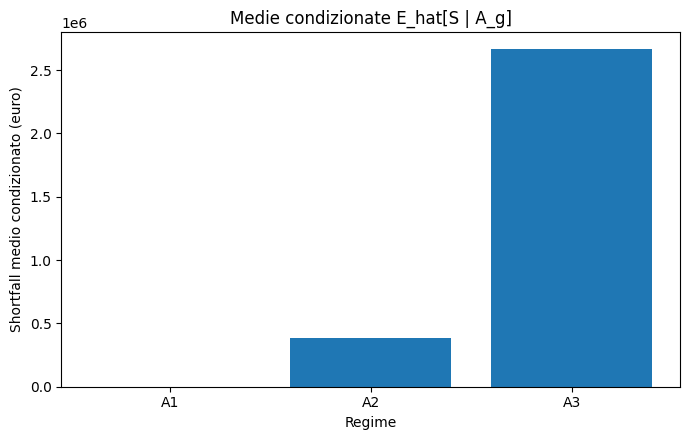

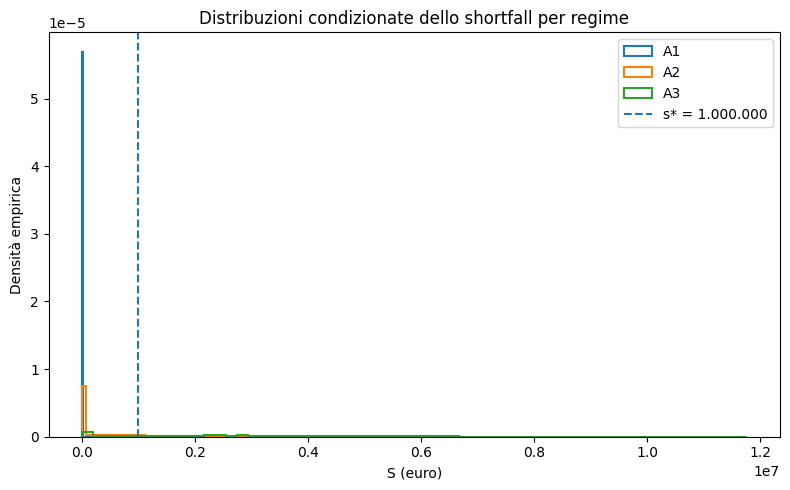

Quadro sintetico dei controlli conclusivi


,Controllo,Esito,Dettaglio
0,1. Somma probabilità teoriche = 1,OK,somma=1.000000000000
1,2. Frequenze empiriche coerenti con probabilità,OK,scarto max=0.00012
2,3. Numerosità sufficiente in ogni regime,OK,"{'A1': 17498, 'A2': 22506, 'A3': 9996}"
3,4. Momenti empirici P_E|A_g coerenti,OK,|scarto media|<1 euro/MWh; |scarto std|<5%
4,5. Presenza di P_E<0 rilevata e non corretta,OK,"n_negativi=2, quota=0.004000%"
5,6. Dimensione dei vettori = n,OK,n=50000
6,7. C_E = Q_E P_E,OK,identità numerica
7,8. M = G0 - Q_E P_E,OK,identità numerica
8,9. S >= 0 e formula della parte positiva,OK,"S=max(m_star-M,0)"
9,10. S=0 quando M>=m_star,OK,verifica su tutte le osservazioni


In [5]:
# Medie condizionate dello shortfall per regime
medie_cond = df.groupby("Regime")["S"].mean().reindex(regimi)

# Frequenze empiriche e contributi alla media globale
freq_emp = df["Regime"].value_counts(normalize=True).reindex(regimi)
contributi_emp = freq_emp * medie_cond
contributi_teorici = prob_regimi.loc[regimi] * medie_cond

tabella_condizionata = pd.DataFrame({
    "Regime": regimi,
    "P_teorica": prob_regimi.loc[regimi].values,
    "P_empirica": freq_emp.loc[regimi].values,
    "E_hat_S_cond": medie_cond.loc[regimi].values,
    "Contributo_media_empirica": contributi_emp.loc[regimi].values,
    "Contributo_media_pesi_teorici": contributi_teorici.loc[regimi].values,
})
print("Medie condizionate e contributi alla media globale")
display(tabella_condizionata)

# Controparte empirica di E[S | G]: variabile casuale a gradini costante su ciascun blocco
mappa_cond = medie_cond.to_dict()
df["E_hat_S_dato_G"] = df["Regime"].map(mappa_cond)
print("Esempio della variabile empirica a gradini E_hat[S | G]")
display(df[["Regime", "S", "E_hat_S_dato_G"]].head(12))

# Verifica del valore atteso totale
media_globale = df["S"].mean()
media_ricomposta_emp = float((freq_emp * medie_cond).sum())
media_ricomposta_teorica = float((prob_regimi.loc[regimi] * medie_cond).sum())

tabella_valore_atteso_totale = pd.DataFrame({
    "Misura": [
        "Media globale campionaria",
        "Media ricomposta con frequenze empiriche",
        "Media ricomposta con probabilità teoriche"
    ],
    "Valore_euro": [media_globale, media_ricomposta_emp, media_ricomposta_teorica],
    "Scarto_da_media_globale": [0.0, media_ricomposta_emp - media_globale, media_ricomposta_teorica - media_globale]
})
print("Verifica del valore atteso totale")
display(tabella_valore_atteso_totale)

# Grafico delle medie condizionate
plt.figure(figsize=(7, 4.5))
plt.bar(regimi, medie_cond.loc[regimi].values)
plt.ylabel("Shortfall medio condizionato (euro)")
plt.xlabel("Regime")
plt.title("Medie condizionate E_hat[S | A_g]")
plt.tight_layout()
plt.show()

# Confronto tra le distribuzioni condizionate dello shortfall
plt.figure(figsize=(8, 5))
for g in regimi:
    valori = df.loc[df["Regime"] == g, "S"]
    plt.hist(valori, bins=60, density=True, histtype="step", linewidth=1.5, label=g)
plt.axvline(s_star, linestyle="--", label="s* = 1.000.000")
plt.xlabel("S (euro)")
plt.ylabel("Densità empirica")
plt.title("Distribuzioni condizionate dello shortfall per regime")
plt.legend()
plt.tight_layout()
plt.show()

# Quadro sintetico dei controlli conclusivi
# Tolleranze Monte Carlo esplicite e diagnostiche, non parte del modello teorico.
controllo_prob = np.isclose(prob_regimi.sum(), 1.0)
controllo_freq = np.max(np.abs(freq_emp - prob_regimi.loc[regimi])) < 0.01
controllo_num = (df["Regime"].value_counts().reindex(regimi) > 1000).all()
controllo_momenti = (
    (np.abs(tabella_controllo_sim["Scarto_media"]) < 1.0).all()
    and (np.abs(tabella_controllo_sim["Scarto_rel_std"]) < 0.05).all()
)
controllo_totale_emp = np.isclose(media_globale, media_ricomposta_emp, rtol=0, atol=1e-8)
controllo_ordine_cond = bool(medie_cond["A1"] < medie_cond["A2"] < medie_cond["A3"])
controllo_parte_positiva_1 = bool((df.loc[df["M"] >= m_star, "S"] == 0).all())
controllo_parte_positiva_2 = np.allclose(
    df.loc[df["M"] < m_star, "S"],
    m_star - df.loc[df["M"] < m_star, "M"]
)

controlli = [
    ("1. Somma probabilità teoriche = 1", controllo_prob, f"somma={prob_regimi.sum():.12f}"),
    ("2. Frequenze empiriche coerenti con probabilità", controllo_freq, f"scarto max={np.max(np.abs(freq_emp - prob_regimi.loc[regimi])):.5f}"),
    ("3. Numerosità sufficiente in ogni regime", controllo_num, str(df["Regime"].value_counts().reindex(regimi).to_dict())),
    ("4. Momenti empirici P_E|A_g coerenti", controllo_momenti, "|scarto media|<1 euro/MWh; |scarto std|<5%"),
    ("5. Presenza di P_E<0 rilevata e non corretta", True, f"n_negativi={n_prezzi_negativi}, quota={quota_prezzi_negativi:.6%}"),
    ("6. Dimensione dei vettori = n", controllo_dimensioni, f"n={n}"),
    ("7. C_E = Q_E P_E", controllo_CE, "identità numerica"),
    ("8. M = G0 - Q_E P_E", controllo_M, "identità numerica"),
    ("9. S >= 0 e formula della parte positiva", controllo_S_nonneg and controllo_S_formula, "S=max(m_star-M,0)"),
    ("10. S=0 quando M>=m_star", controllo_parte_positiva_1, "verifica su tutte le osservazioni"),
    ("11. S=m_star-M quando M<m_star", controllo_parte_positiva_2, "verifica su tutte le osservazioni"),
    ("12. S>0 <=> P_E>120", controllo_soglia_pos, "equivalenza campionaria"),
    ("13. S>s_star <=> P_E>140", controllo_soglia_severa, "equivalenza campionaria"),
    ("14. Media globale = media ricomposta empirica", controllo_totale_emp, f"scarto={media_ricomposta_emp-media_globale:.6e}"),
    ("15. Quantili ordinati", controllo_quantili, str(quantili_S.to_dict())),
    ("16. Media tra minimo e massimo campionario", controllo_media_range, f"min={df['S'].min():.2f}, media={media_globale:.2f}, max={df['S'].max():.2f}"),
    ("17. Ordine economico delle medie condizionate A1<A2<A3", controllo_ordine_cond, str(medie_cond.to_dict())),
]

tabella_controlli_finali = pd.DataFrame(controlli, columns=["Controllo", "Esito_booleano", "Dettaglio"])
tabella_controlli_finali["Esito"] = np.where(tabella_controlli_finali["Esito_booleano"], "OK", "DA VERIFICARE")
print("Quadro sintetico dei controlli conclusivi")
display(tabella_controlli_finali[["Controllo", "Esito", "Dettaglio"]])

if not tabella_controlli_finali["Esito_booleano"].all():
    raise AssertionError("Almeno un controllo conclusivo richiede verifica.")

## Tappa 6 — Interpretazione critica e limiti

L'esecuzione riproducibile con seed `24680` produce una struttura dei risultati coerente con la calibrazione del caso.

### Lettura degli output

1. **Regime $A_1$ — Normalizzazione energetica.** Lo shortfall medio condizionato è sostanzialmente nullo rispetto alla scala del problema: la maggior parte delle simulazioni resta al di sotto della soglia di prezzo che genera shortfall. Non significa che il costo energetico sia nullo; significa che il margine resta, nella maggior parte dei casi, almeno pari a $m^\star$.

2. **Regime $A_2$ — Tensione persistente.** Lo shortfall medio è positivo e intermedio. Il prezzo medio del regime è prossimo alla soglia di $120$ euro/MWh e la dispersione fa sì che una quota significativa delle osservazioni produca shortfall.

3. **Regime $A_3$ — Shock energetico severo.** Lo shortfall medio condizionato è nettamente più elevato e la distribuzione è più dispersa. Questo è coerente con il livello medio e con la deviazione standard più elevati di $P_E\mid A_3$.

4. **Massa in zero.** La distribuzione di $S$ presenta una massa in zero perché $S$ è definito mediante parte positiva. Le osservazioni con $M\ge m^\star$ non generano shortfall, anche se presentano comunque un costo energetico positivo o, eccezionalmente nel modello normale, un prezzo simulato negativo.

5. **Informazione di regime.** Le quantità $\widehat{\mathbb E}[S\mid A_g]$ sono tre numeri. La colonna `E_hat_S_dato_G` rappresenta invece la controparte empirica della variabile casuale $\mathbb E[S\mid\mathcal G]$: per ogni osservazione assume la media condizionata del blocco informativo al quale l'osservazione appartiene. La media globale $\widehat{\mathbb E}[S]$ è un ulteriore oggetto, non condizionato.

6. **Valore atteso totale.** La media globale campionaria coincide con la ricomposizione ottenuta usando frequenze empiriche e medie condizionate. L'uso delle probabilità teoriche produce una quantità molto vicina, con uno scarto riconducibile all'errore Monte Carlo.

### Limiti del modello

- $G_0$ e $Q_E$ sono fissati e l'unica fonte di incertezza è $P_E$.
- Il costo energetico è lineare nel prezzo e non sono modellati ricavi aleatori, elasticità della produzione, hedging, contratti a termine o dinamica multiperiodale.
- Le distribuzioni normali condizionate possono generare prezzi negativi. Il notebook li rileva e li lascia invariati, trattandoli come **limite della specificazione**, non come osservazioni da correggere automaticamente.
- La simulazione non è una previsione del prezzo dell'energia e i parametri hanno finalità didattica.
- L'informazione di regime modifica la distribuzione condizionata rilevante, ma non elimina l'incertezza residua all'interno di ciascun regime.

La conclusione economico-quantitativa è quindi coerente con la domanda del caso: il rischio di shortfall cambia in misura rilevante al variare dell'informazione di regime, con $A_1$ caratterizzato da shortfall quasi nullo, $A_2$ da una situazione intermedia e $A_3$ dal livello di shortfall atteso più elevato.